# Initialization of the hyperparameters

This page studies how the start values of the hyperparameters change the
training with a gradient optimizer, such as Adam. CMA-ES, the default
optimizer, ignores the initializer.
[Choose an initialization method][choose-an-initialization-method] gives
the short rules.

## Motivation

Training a parametric prior requires an initial value for each hyperparameter.
This is where the training algorithm starts, and ideally it does not lie too
far from an optimal point in the loss landscape. Consider a simple case with a
single global optimum: the further the initial value lies from that optimum,
the more steps the algorithm needs before it converges.

The difficulty is that we use a method like `elicito` precisely because we do
not know the hyperparameter values. Finding them is the goal. This makes a good
initial value hard to choose.

Moreover, the statistical models we work with rarely give rise to a simple loss
landscape with a single global optimum. Their landscapes are usually far more
complex, which makes a sensible starting point even harder to identify. In such
a case a poor initial value does more than prolong the training: it can cause
numerical instability, and NAN values that stop the run altogether.

We therefore need a systematic way to choose initial values. This guide
presents three such methods, and explains when each one is appropriate.

In part 1 we use a simple normal model with known variance, and a prior on the
location parameter $\mu$. This leaves two hyperparameters: the prior location
$\mu_0$ and the prior scale $\sigma_0$. The example is deliberately chosen so
that the loss landscape is simple and has a single global optimum, which makes
it easier to build an intuition for how the methods behave.

In part 2 we turn to a considerably harder example, with a Weibull likelihood
and six hyperparameters to train.

We close with general recommendations for choosing an initialization method.

## Imports

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import time
from functools import partial
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import tensorflow_probability as tfp

import elicito as el

tfd = tfp.distributions

## Part 1: a model with two hyperparameters

We start with a highly simplified example. The statistical model consists of a
Normal likelihood with known variance, and a Normal prior on the location
parameter $\mu$:
$$
\begin{align*}
    \lambda &= (\mu_0, \sigma_0) \\
    \mu &\sim \text{Normal}(\mu_0, \sigma_0) \\
    y &\sim \text{Normal}(\mu, 1)
\end{align*}
$$
The goal is to learn the two prior hyperparameters $\lambda$: $\mu_0$ and
$\sigma_0$. We simulate the expert information, so we know the ground truth.
The true values are $\mu_0 = 1$ and $\sigma_0 = 2$. A scale is learned on the
unconstrained scale, so the true value of $\sigma_0$ in every figure below is
$\text{softplus}^{-1}(2) = 1.85$.

As training data we give the algorithm five quantiles of $y$.

In [2]:
class NormalModel:
    """Generative model of part 1"""

    def __call__(self, prior_samples: Any, N: int) -> dict[str, Any]:
        """
        Compute the target quantities

        Parameters
        ----------
        prior_samples
            samples from the prior distributions

        N
            number of observations

        Returns
        -------
        :
            dictionary with the target quantities
        """
        mu = prior_samples[:, :, 0][:, :, None]
        ypred = tfd.Normal(
            loc=tf.broadcast_to(mu, (*mu.shape[:2], N)), scale=1.0
        ).sample()

        return dict(ypred=ypred, prior_samples=prior_samples, y=ypred[:, :, 0])

In [3]:
parameters = [
    el.parameter(
        name="mu",
        family=tfd.Normal,
        hyperparams=dict(loc=el.hyper("mu0"), scale=el.hyper("sigma0", lower=0)),
    )
]

PROBS = (0.05, 0.25, 0.50, 0.75, 0.95)

targets = [el.quantiles("y", probs=PROBS)]

ground_truth = {"mu": tfd.Normal(loc=1.0, scale=2.0)}
expert = el.expert.simulator(ground_truth=ground_truth, num_samples=10_000)

forward = el.parameters.LowerBound(lower=0.0).forward
# the true values, on the scale of the figures
TRUTH = (1.0, float(forward(2.0)))

In [4]:
def build(
    initializer: Any, epochs: int = 300, B: int = 128, num_samples: int = 200
) -> el.Elicit:
    """
    Build the eliobj; only the initializer changes between the sections

    Parameters
    ----------
    initializer
        initialization method, as returned by
        [`initializer`][elicito.initializers.spec.initializer]

    epochs
        number of training epochs

    B
        batch size

    num_samples
        number of prior draws per batch

    Returns
    -------
    :
        the unfitted eliobj
    """
    return el.Elicit(
        partial(NormalModel(), N=50),
        targets,
        parameters,
        initializer=initializer,
        optimizer="adam",
        seeds=(0,),
        epochs=epochs,
        B=B,
        num_samples=num_samples,
        verbose=False,
    )


def fit_and_report(
    label: str,
    initializer: Any,
    epochs: int = 300,
    B: int = 128,
    num_samples: int = 200,
) -> float:
    """
    Fit the model, store it, and report the final loss

    Parameters
    ----------
    label
        name of the initialization method, used in the summary table

    initializer
        initialization method

    epochs
        number of training epochs

    B
        batch size

    num_samples
        number of prior draws per batch

    Returns
    -------
    :
        the final loss
    """
    eliobj = build(initializer, epochs, B, num_samples)
    start = time.time()
    eliobj.fit(expert)
    seconds = time.time() - start
    loss = float(np.ravel(eliobj.results.history_stats.loss.total_loss.values)[-1])
    print(f"{label}: final loss {loss:.3f} in {seconds:.1f}s")
    results.append((label, loss, seconds))
    fits[label] = eliobj
    return loss


results: list[tuple[str, float, float]] = []
fits: dict[str, el.Elicit] = {}

### The loss surface

The figure below shows the loss surface of the model, as a function of the two
hyperparameters $\mu_0$ and $\sigma_0$. The colors represent the log10 of the
loss, and a darker color is a lower loss. We see the global minimum at the true
values of the hyperparameters, which are marked with a white star.

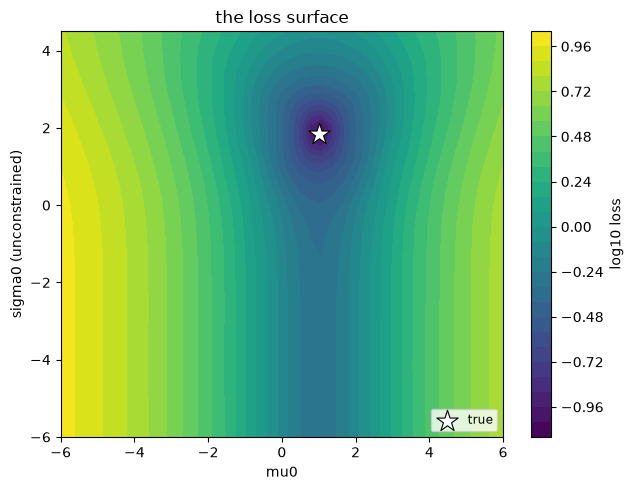

In [5]:
eliobj = build(el.initializer(hyperparams=dict(mu0=1.0, sigma0=0.0)))
expert_elicits, _ = el.utils.get_expert_data(
    eliobj.trainer,
    eliobj.model,
    eliobj.targets,
    expert,
    eliobj.parameters,
    eliobj.network,
    eliobj.trainer["seed"],
)

mu0_grid = np.linspace(-6.0, 6.0, 40)
sigma0_grid = np.linspace(-6.0, 4.5, 40)


def loss_grid(mu0_values: Any, sigma0_values: Any) -> Any:
    """
    Compute the loss on a grid of the two hyperparameters

    Parameters
    ----------
    mu0_values
        grid points of mu0

    sigma0_values
        grid points of sigma0, on the unconstrained scale

    Returns
    -------
    :
        the loss, shape (sigma0 points, mu0 points)
    """
    grid = np.empty((len(sigma0_values), len(mu0_values)))
    for i, sigma0_value in enumerate(sigma0_values):
        for j, mu0_value in enumerate(mu0_values):
            grid[i, j] = el.optimizers.search.score(
                hyperparams=dict(mu0=mu0_value, sigma0=sigma0_value),
                expert_elicited_statistics=expert_elicits,
                parameters=eliobj.parameters,
                trainer=eliobj.trainer,
                model=eliobj.model,
                targets=eliobj.targets,
                expert=expert,
                seed=0,
            )
    return grid


surface = loss_grid(mu0_grid, sigma0_grid)


def landscape(  # noqa: PLR0913
    title: str,
    candidates: Any = None,
    start: Any = None,
    path: Any = None,
    search: Any = None,
    wide: bool = False,
) -> None:
    """
    Draw the loss surface, and what one initialization method did on it

    Parameters
    ----------
    title
        title of the figure

    candidates
        start values the method drew, shape (candidates, 2)

    start
        the start value the method picked

    path
        the training path, shape (epochs, 2)

    search
        the points a search evaluated, shape (evaluations, 2)

    wide
        with ``True`` the figure uses the extended surface, which reaches down
        to sigma0 of -11. The default is the surface of the section above.
    """
    fig, ax = plt.subplots(figsize=(6.5, 5), layout="tight")
    y_grid = sigma0_wide if wide else sigma0_grid
    z_grid = surface_wide if wide else surface
    drawn = ax.contourf(mu0_grid, y_grid, np.log10(z_grid), levels=30, cmap="viridis")
    if candidates is not None:
        ax.scatter(
            candidates[:, 0],
            candidates[:, 1],
            s=25,
            color="white",
            edgecolor="0.3",
            linewidth=0.5,
            label="candidates",
        )
    if search is not None:
        ax.plot(
            search[:, 0],
            search[:, 1],
            color="white",
            linewidth=1.0,
            marker="o",
            markersize=3,
            label="search",
        )
    if path is not None:
        ax.plot(
            path[:, 0], path[:, 1], color="crimson", linewidth=1.5, label="training"
        )
        ax.scatter(path[-1, 0], path[-1, 1], marker="o", s=60, color="crimson")
    if start is not None:
        ax.scatter(start[0], start[1], marker="o", s=70, color="black", label="start")
    ax.scatter(
        TRUTH[0],
        TRUTH[1],
        marker="*",
        s=260,
        color="white",
        edgecolor="black",
        linewidth=0.8,
        label="true",
    )
    ax.set_xlim(mu0_grid[0], mu0_grid[-1])
    ax.set_ylim(y_grid[0], y_grid[-1])
    ax.set_xlabel("mu0")
    ax.set_ylabel("sigma0 (unconstrained)")
    ax.set_title(title)
    ax.legend(fontsize="small", loc="lower right")
    fig.colorbar(drawn, ax=ax, label="log10 loss")
    plt.show()


def candidates_of(label: str) -> tuple[Any, Any]:
    """
    Read the candidates of a fit, and the one it picked

    Parameters
    ----------
    label
        name used in [`fit_and_report`][fit_and_report]

    Returns
    -------
    :
        the candidates and the picked start value
    """
    init = fits[label].results.initialization.sel(replication=0)
    names = [str(n) for n in init.hyperparameters.coords["hyperparameter"].values]
    drawn = np.asarray(init.hyperparameters.values)[
        :, [names.index("mu0"), names.index("sigma0")]
    ]
    losses = np.ravel(np.asarray(init.loss.values))
    return drawn, drawn[int(np.nanargmin(losses))]


def training_path(label: str) -> Any:
    """
    Read the training path of a fit, on the unconstrained scale

    Parameters
    ----------
    label
        name used in [`fit_and_report`][fit_and_report]

    Returns
    -------
    :
        the path, shape (epochs, 2)
    """
    history = fits[label].results.history_stats.hyperparameter.sel(replication=0)
    return np.column_stack(
        [
            np.ravel(history["mu0"].values),
            np.asarray(forward(np.ravel(history["sigma0"].values))),
        ]
    )


landscape("the loss surface")

In the following sections we present the initialization methods that `elicito`
implements. For each one we discuss the intuition, show how you call it, and
watch it on the loss surface above.

### Option 1: Provide exact values
#### Intuition
The easiest approach is to provide the exact hyperparameter values from which
the learning algorithm starts. Note that you provide these values on the
unconstrained scale. A hyperparameter that is already unconstrained, like
$\mu_0$, you give directly. A constrained hyperparameter, like $\sigma_0$ in
this example, you first transform with the inverse of the constraint function,
for example `softplus`.

#### Implementation
In `elicito` you provide exact values as a dictionary, through the
`hyperparams` argument of `el.initializer()`. For the transformation to the
unconstrained scale, `elicito` gives you these utilities:

  + a lower-bounded hyperparameter:
    `el.parameters.LowerBound(lower=0.0).forward(value)`
  + an upper-bounded hyperparameter:
    `el.parameters.UpperBound(upper=1.0).forward(value)`
  + a double-bounded hyperparameter:
    `el.parameters.DoubleBound(lower=0.0, upper=1.0).forward(value)`

#### Visualization (Example)
The plot below shows the initialization and the training for this approach. The
black dot is the initial value, here $\mu_0 = 1.5$ and
$\sigma_0 = \text{softplus}^{-1}(2.5)$. The red line is the learning trajectory
over the epochs. We see that it follows the gradient towards the global
minimum, which is marked with a star.

In [6]:
loss = fit_and_report(
    "exact values",
    el.initializer(
        hyperparams=dict(
            mu0=1.5, sigma0=el.parameters.LowerBound(lower=0.0).forward(2.5)
        )
    ),
)

exact values: final loss 0.088 in 4.6s


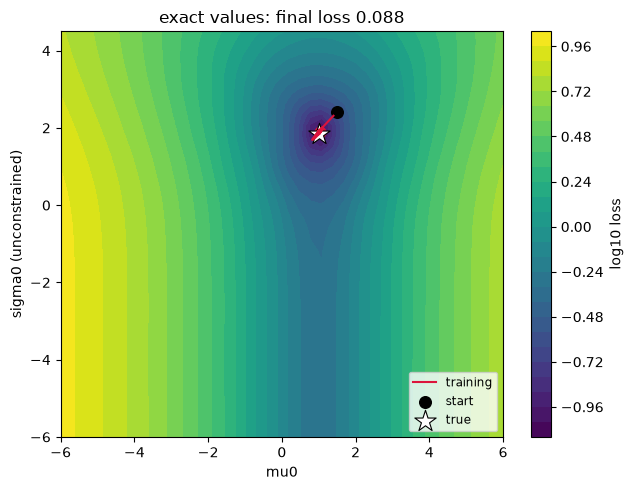

In [7]:
landscape(
    f"exact values: final loss {loss:.3f}",
    start=(1.5, forward(2.5)),
    path=training_path("exact values"),
)

### Option 2: Provide a region of possible values
#### Intuition
Exact values are usually hard to specify, but you might be able to give a
region of possible values from which the algorithm samples. Earlier
experiments, for example, can tell you the approximate range.

You then provide the center of this plausible region, and a radius that sets
its size. The method samples candidates from the region and evaluates the loss
of each one. The candidate with the lowest loss becomes the starting point of
the training.

#### Implementation
In `elicito` you specify the region with `el.initializers.uniform()`, which
you pass to the `distribution` argument. It spans a uniform box around a center
point, with a given radius. The `method` argument sets how the candidates are
drawn from the box: `"sobol"`, `"lhs"` (Latin Hypercube Sampling), or
`"random"`. The `iterations` argument sets how many candidates are drawn.

#### Visualization (Example)
For the example below we specify a uniform box with a radius of 1 around the
center point (0, 0). The white points in the figure are the candidates, spread
evenly over the plausible region. Among them, the point with the lowest loss
becomes the starting point of the training (black dot). From there the
trajectory (red line) moves towards the global minimum (star).

In [8]:
loss = fit_and_report(
    "uniform box",
    el.initializer(
        method="sobol",
        iterations=32,
        distribution=el.initializers.uniform(radius=1, mean=0),
    ),
)

uniform box: final loss 0.088 in 5.7s


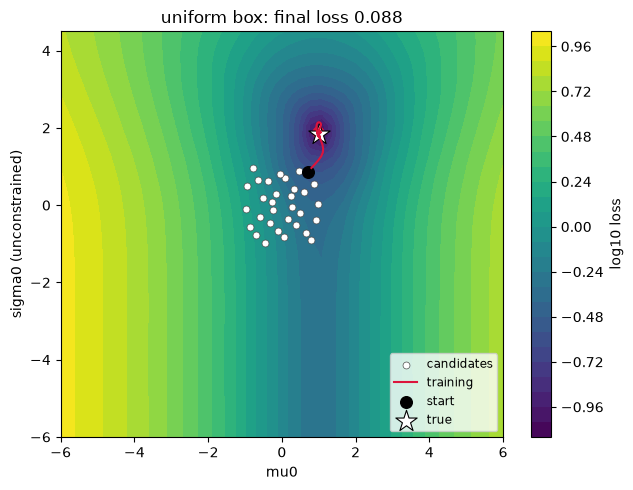

In [9]:
drawn, start = candidates_of("uniform box")
landscape(
    f"uniform box: final loss {loss:.3f}",
    candidates=drawn,
    start=start,
    path=training_path("uniform box"),
)

### Option 2: Provide a region of possible values (that is far away)
In the example above the region lies close to the global minimum, and the
method works well. But what happens when the region lies far away from it? We
investigate this case in more detail below. We start with a uniform box that is
centered at (-4, -4), with a radius of 1, so it lies far from the global
minimum. The figure below shows the result.

In [10]:
loss = fit_and_report(
    "far box",
    el.initializer(
        method="sobol",
        iterations=32,
        distribution=el.initializers.uniform(radius=1, mean=-4),
    ),
    epochs=300,
)

far box: final loss 0.088 in 5.7s


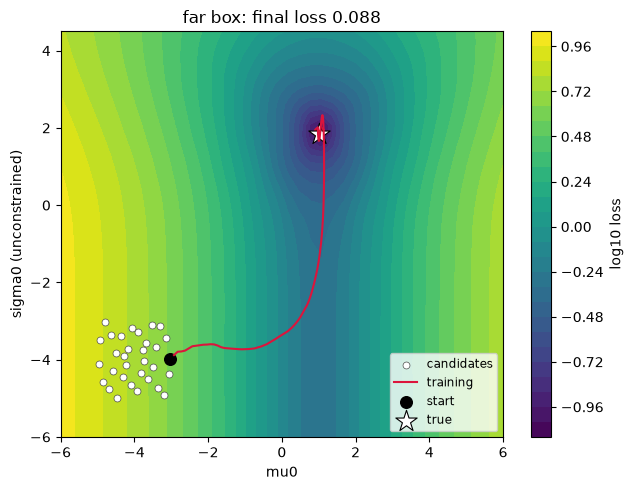

In [11]:
drawn, start = candidates_of("far box")
landscape(
    f"far box: final loss {loss:.3f}",
    candidates=drawn,
    start=start,
    path=training_path("far box"),
)

The training starts on a flat floor, at $\sigma_0 = -3.9$. It first learns
$\mu_0$, which has a clear gradient: $\mu_0$ crosses zero at about epoch 33.
Then it leaves the floor. The loss is within 5% of its final value at epoch 86,
and the run ends at the same loss as the box near the minimum.

On the floor, the gradient in $\sigma_0$ is small. Two effects cause this. The
predictive standard deviation is $\sqrt{\text{scale}^2 + 1}$, so a small scale
disappears behind the noise of 1. And the softplus saturates, so
$d\,\text{scale} / d\sigma_0 = \text{sigmoid}(\sigma_0)$ is small as well. The
training learns $\sigma_0$ only while this effect is larger than the error of
the loss estimate. A box on the floor therefore costs epochs.

### Option 3: Search for a start value (default)
#### Intuition
Sometimes you know neither exact values, nor a region that contains them. The
algorithm can then search for a start value itself, before the first gradient
step. The search is a Nelder-Mead search on the unconstrained hyperparameters.
It evaluates the same loss on fewer prior draws, and it needs no gradient, so
it cannot diverge through an exploding gradient. A point whose draws overflow
is never returned.

#### Implementation
In `elicito` you select the search with `method="warmstart"`. The `iterations`
argument is now the budget of the search, in objective evaluations, and not a
number of candidates. The center of `distribution` is the start point of the
search, so pass `el.initializers.uniform()` when you want to set that point
yourself.

If you pass no `distribution`, `elicito` uses
[`uniform`][elicito.initializers.sampling.uniform] with its defaults, `mean=0` and
`radius=1`, on the unconstrained scale. This is what `el.initializer()` does
with no argument at all: `method="warmstart"`, the default `uniform` box, and
a budget of 100 evaluations.

#### Visualization (Example)
We give the search the far box of option 2. The center of that box is the start
point of the search. The budget is 50 evaluations, because we search only two
hyperparameters here. The search itself is not stored, so the figure below
records it: we wrap [`compile_score`][elicito.optimizers.search.compile_score], the
function that builds the scorer of the search, for the time of the fit.

The white path is the search, the black dot is the start value that it returns,
and the red line is the training. The search leaves the box, and it also leaves
the frame of the figures above: it reaches $\sigma_0 = -6.7$, while the surface
above stops at $-6$. This figure therefore extends the loss downwards, on the
same grid.

The start value that the search returns is $\mu_0 = 1.08$, close to the true 1,
and $\sigma_0 \approx -5.8$, deeper on the flat floor than the box. On that
floor the loss hardly responds to $\sigma_0$, so the search has no reason to
leave it. The training then stays on the floor: the loss is near 0.49 until
about epoch 200. The run reaches the same 0.088 as every other method of part
1, but only after about 230 epochs. Sampling from the same box got there at
epoch 86.

In [12]:
# the search leaves the frame of the figures above, so extend the surface
# downwards, with the step of the grid above
step = float(sigma0_grid[1] - sigma0_grid[0])
sigma0_low = np.arange(sigma0_grid[0] - step, -11.0 - step, -step)[::-1]
sigma0_wide = np.concatenate([sigma0_low, sigma0_grid])
surface_wide = np.vstack([loss_grid(mu0_grid, sigma0_low), surface])

In [13]:
visited: list[Any] = []
scored: list[float] = []
original_compile = el.optimizers.search.compile_score


def recording_compile(*args: Any, **kwargs: Any) -> Any:
    """Build the scorer as usual, then record each evaluation of the search"""
    scorer = original_compile(*args, **kwargs)

    def recording(hyperparams: dict[str, Any]) -> float:
        value = float(scorer(hyperparams))
        visited.append(list(hyperparams.values()))
        scored.append(value)
        return value

    return recording


el.optimizers.search.compile_score = recording_compile

In [14]:
loss = fit_and_report(
    "warmstart",
    el.initializer(
        method="warmstart",
        iterations=50,
        distribution=el.initializers.uniform(radius=1, mean=-4),
    ),
)

warmstart: final loss 0.088 in 4.4s


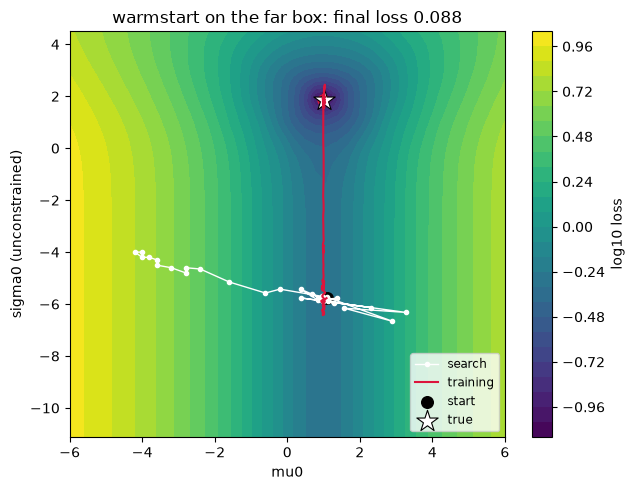

In [15]:
el.optimizers.search.compile_score = original_compile

path = training_path("warmstart")
landscape(
    f"warmstart on the far box: final loss {loss:.3f}",
    start=path[0],
    path=path,
    search=np.asarray(visited),
    wide=True,
)

### What part 1 showed

Every method of part 1 reaches the same loss, 0.088. On a surface with one
minimum, the start value only decides how many epochs the training needs.

The far box shows that a search is not always the faster start. The search
fixes $\mu_0$, and it leaves $\sigma_0$ deep on the flat floor, where the
training needs about 200 epochs to find the gradient. Sampling from the same
box started higher on the floor, and was done by epoch 86.

In [16]:
print(f"{'method':21s} {'final loss':>10s} {'seconds':>9s}")
for label, final_loss, seconds in results:
    print(f"{label:21s} {final_loss:10.3f} {seconds:9.1f}")

method                final loss   seconds
exact values               0.088       4.6
uniform box                0.088       5.7
far box                    0.088       5.7
warmstart                  0.088       4.4


### When a hyperparameter has a small effect

The far box is one case of a rule that holds beyond initialization. The
training learns a hyperparameter only while its effect on the loss is larger
than the error of the loss estimate. `B` and `num_samples` shrink that error as
$1/\sqrt{B \cdot \text{num\_samples}}$, so an effect half as large costs four
times the sample.

Before you pay that, ask why the effect is small.

+ **The parameterization hides it.** At $\sigma_0 = -4.5$ the softplus
  contributes a factor $0.011$ for no other reason than saturation. A start
  value higher on the floor is far cheaper than a larger sample: the sampled
  far box above is done by epoch 86, and the warm start, deeper on the floor,
  needs about 230.
+ **The elicited statistics do not respond to it.** A larger sample then
  sharpens a direction that the data cannot pin down. Part 2 shows this: $k_2$
  ends near 7 against a true 2, and that run still has a lower loss than the
  run from the true values. The fix is a query that responds, for example on
  the parameter itself.

Raise `B` and `num_samples` when the effect is real but buried. Change the
start value, or the query, when the effect is not there to begin with.

In the next part we use a model where this is no longer true. A bad start value
there does not merely cost epochs. It produces draws that overflow, and the
training cannot start at all.

## Part 2: a model that can overflow

The surface of part 1 had a gradient everywhere, so a poor start value only
cost epochs. We now use a model where a start value can be unusable: the draws
overflow, the loss is NAN, and there is nothing to descend. We learn six
hyperparameters, so we cannot draw a surface. The figures hold four of them at
their true values, and draw the loss of the other two.

### The model

$$
\begin{align*}
    \beta_0 &\sim \text{Normal}(\mu_0, \sigma_0) \\
    \beta_1 &\sim \text{Normal}(\mu_1, \sigma_1) \\
    k &\sim \text{Weibull}(k_2, \lambda_2) \\
    y &\sim \text{Weibull}(k, \lambda),
        \quad \lambda = \frac{\exp(\beta_0 + \beta_1 X)}{\Gamma(1 + 1/k)}
\end{align*}
$$

The likelihood follows the `brms` defaults for the Weibull family: a log link,
and a mean parameterization. The linear predictor is therefore the log of the
mean of $y$, and not the log of the Weibull scale.

The prior of the shape $k$ is a Weibull, and not a HalfNormal. A HalfNormal
puts mass at $k \approx 0$, where $\Gamma(1 + 1/k)$ overflows and the
likelihood scale becomes zero. The loss is then NAN, even at the true
hyperparameters.

We learn the six hyperparameters $\mu_0, \sigma_0, \mu_1, \sigma_1, k_2,
\lambda_2$, and we query an oracle for the quantiles of $y$ at three values of
the predictor.

In [17]:
def std_predictor(N: int, quantiles: list[int]) -> Any:
    """
    Compute a standardized predictor

    Parameters
    ----------
    N
        number of observations

    quantiles
        quantiles of the predictor used for the queries

    Returns
    -------
    :
        selected values of the standardized predictor
    """
    X = tf.cast(np.arange(N), tf.float32)
    X_std = (X - tf.reduce_mean(X)) / tf.math.reduce_std(X)
    return tfp.stats.percentile(X_std, quantiles)


class ToyModel:
    """Generative model of the guide"""

    def __call__(self, prior_samples: Any, design_matrix: Any) -> dict[str, Any]:
        """
        Compute the target quantities

        Parameters
        ----------
        prior_samples
            samples from the prior distributions

        design_matrix
            selected values of the predictor

        Returns
        -------
        :
            dictionary with the target quantities
        """
        B, S = prior_samples.shape[0], prior_samples.shape[1]
        X = tf.broadcast_to(design_matrix[None, None, :], (B, S, len(design_matrix)))

        eta = tf.add(
            prior_samples[:, :, 0][:, :, None],
            tf.multiply(prior_samples[:, :, 1][:, :, None], X),
        )
        # the log link gives the mean of y; the shape k turns it into the scale
        epred = tf.exp(eta)
        k = tf.expand_dims(prior_samples[:, :, -1], -1)
        scale = epred / tf.exp(tf.math.lgamma(1.0 + 1.0 / k))
        likelihood = tfd.Weibull(concentration=k, scale=scale)
        ypred = likelihood.sample()

        return dict(
            ypred=ypred,
            epred=epred,
            prior_samples=prior_samples,
            y_X0=ypred[:, :, 0],
            y_X1=ypred[:, :, 1],
            y_X2=ypred[:, :, 2],
        )

In [18]:
parameters = [
    el.parameter(
        name="beta0",
        family=tfd.Normal,
        hyperparams=dict(loc=el.hyper("mu0"), scale=el.hyper("sigma0", lower=0)),
    ),
    el.parameter(
        name="beta1",
        family=tfd.Normal,
        hyperparams=dict(loc=el.hyper("mu1"), scale=el.hyper("sigma1", lower=0)),
    ),
    el.parameter(
        name="k",
        family=tfd.Weibull,
        hyperparams=dict(
            concentration=el.hyper("k2", lower=0),
            scale=el.hyper("lambda2", lower=0),
        ),
    ),
]

PROBS = (0.05, 0.25, 0.50, 0.75, 0.95)

targets = [el.quantiles(name, probs=PROBS) for name in ("y_X0", "y_X1", "y_X2")]

ground_truth = {
    "beta0": tfd.Normal(loc=1.0, scale=0.5),
    "beta1": tfd.Normal(loc=0.3, scale=0.2),
    "k": tfd.Weibull(concentration=2.0, scale=5.0),
}
expert = el.expert.simulator(ground_truth=ground_truth, num_samples=10_000)

In [19]:
def build(initializer: Any, epochs: int = 100) -> el.Elicit:
    """
    Build the eliobj; only the initializer changes between the sections

    Parameters
    ----------
    initializer
        initialization method, as returned by
        [`initializer`][elicito.initializers.spec.initializer]

    epochs
        number of training epochs

    Returns
    -------
    :
        the unfitted eliobj
    """
    return el.Elicit(
        partial(ToyModel(), design_matrix=std_predictor(N=200, quantiles=[25, 50, 75])),
        targets,
        parameters,
        initializer=initializer,
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.1, clipnorm=1.0),
        seeds=(0,),
        epochs=epochs,
        verbose=False,
    )


def fit_and_report(label: str, initializer: Any) -> tuple[str, float, float]:
    """
    Fit the model and read the final loss

    Parameters
    ----------
    label
        name of the initialization method, used in the summary table

    initializer
        initialization method

    Returns
    -------
    :
        the label, the final loss and the runtime in seconds
    """
    eliobj = build(initializer)
    start = time.time()
    eliobj.fit(expert)
    seconds = time.time() - start
    loss = float(np.ravel(eliobj.results.history_stats.loss.total_loss.values)[-1])
    print(f"{label}: final loss {loss:.3f} in {seconds:.1f}s")
    fits[label] = eliobj
    return label, loss, seconds


results = []
fits = {}

# The true values. The training records a hyperparameter on its natural scale,
# so the convergence figure uses these. The two search figures work on the
# unconstrained scale, so they use `truth_unconstrained` below.
truth = dict(mu0=1.0, sigma0=0.5, mu1=0.3, sigma1=0.2, k2=2.0, lambda2=5.0)

forward = el.parameters.LowerBound(lower=0.0).forward
truth_unconstrained = dict(
    mu0=1.0,
    sigma0=float(forward(0.5)),
    mu1=0.3,
    sigma1=float(forward(0.2)),
    k2=float(forward(2.0)),
    lambda2=float(forward(5.0)),
)

# the figures cut the loss along two of the fifteen pairs of hyperparameters
projections = [("mu0", "sigma0"), ("k2", "lambda2")]

### A box that stops the training

The true values on the unconstrained scale are $\mu_0=1, \sigma_0=-0.43,
\mu_1=0.3, \sigma_1=-1.51, k_2=1.85, \lambda_2=4.99$.

A box centered at $-20$ contains none of them. Every scale collapses to
$\text{softplus}(-20) \approx 0$, the shape $k$ goes to zero, and
$\Gamma(1 + 1/k)$ overflows. No candidate of the box is usable, so `fit` raises
an error instead of starting.

In [20]:
try:
    fit_and_report(
        "bad box",
        el.initializer(
            method="sobol",
            iterations=32,
            distribution=el.initializers.uniform(radius=2, mean=-20),
        ),
    )
except ValueError as error:
    print(error)

All 32 initialization candidates yield a non-finite loss, so no start value can be selected. The initialization distribution is centred at -20 with radius 2, on the unconstrained scale. Re-centre it on the expected hyperparameter values, or reduce its radius.


### Option 1: exact values

We now give six values, instead of two.

In [21]:
results.append(
    fit_and_report(
        "exact values",
        el.initializer(
            hyperparams=dict(
                mu0=1.0,
                sigma0=el.parameters.LowerBound(lower=0.0).forward(0.5),
                mu1=0.3,
                sigma1=el.parameters.LowerBound(lower=0.0).forward(0.2),
                k2=el.parameters.LowerBound(lower=0.0).forward(2.0),
                lambda2=el.parameters.LowerBound(lower=0.0).forward(5.0),
            )
        ),
    )
)

exact values: final loss 0.262 in 1.0s


### Option 2: sample a box

`uniform()` on its own, `mean=0` with `radius=1`, already raises an error here.
The Weibull concentration is then $\text{softplus}(k_2) \in [0.31, 1.31]$, many
draws of $k$ fall near zero, and $\Gamma(1 + 1/k)$ overflows. We therefore
center the box below at 2, which covers the six true values.

In [22]:
results.append(
    fit_and_report(
        "uniform box",
        el.initializer(
            method="sobol",
            iterations=32,
            distribution=el.initializers.uniform(radius=3, mean=2),
        ),
    )
)

uniform box: final loss 2.361 in 4.0s


### Option 3: search the start value

This is the model that the search is made for. It needs no gradient, and it
never returns a point whose draws overflow. The budget is 100 evaluations here,
against 50 in part 1, because we search six hyperparameters instead of two. A
budget that does not grow with the number of hyperparameters leaves the search
short: at 50 evaluations it stops at a start value of loss 9.9, and the
training then needs 140 epochs to recover.

The `compile_score` wrapper of part 1 records the path again.

In [23]:
visited = []
scored = []
el.optimizers.search.compile_score = recording_compile

In [24]:
results.append(
    fit_and_report(
        "warmstart",
        el.initializer(
            method="warmstart",
            iterations=100,
            distribution=el.initializers.uniform(radius=3, mean=2),
        ),
    )
)

warmstart: final loss 0.278 in 3.1s


In [25]:
el.optimizers.search.compile_score = original_compile

### Comparison

Read this table together with the log above. Two of the three runs stopped
early, `exact values` and `uniform box`: each has a loss trace of 5 epochs. The
loss of those two is the last finite loss, and not the loss after 100 epochs.
Even the true hyperparameters do not give a stable trajectory for this model.

In [26]:
print(f"{'method':21s} {'final loss':>10s} {'seconds':>9s}")
for label, loss, seconds in results:
    print(f"{label:21s} {loss:10.3f} {seconds:9.1f}")

method                final loss   seconds
exact values               0.262       1.0
uniform box                2.361       4.0
warmstart                  0.278       3.1


### Watch the search

In part 1 we drew every method on the loss surface. Six hyperparameters have no
surface, so we hold four of them at their true values. The loss of the other
two is a plane again, and we draw it exactly as in part 1. The two slices are
$(\mu_0, \sigma_0)$ and $(k_2, \lambda_2)$.

A slice is a cut through the surface, and not the surface itself. A point that
lies in a dark region of the cut can still be poor in the four held directions.
The cut does show what part 1 had no example of: the gray region, where the
draws overflow and there is no loss to descend.

Each slice costs 900 evaluations, which is about 80 seconds.

In [27]:
init = fits["uniform box"].results.initialization.sel(replication=0)
names = [str(n) for n in init.hyperparameters.coords["hyperparameter"].values]
candidates = np.asarray(init.hyperparameters.values)
losses = np.ravel(np.asarray(init.loss.values))
failed = ~np.isfinite(losses)

search_path = np.asarray(visited)
scores = np.asarray(scored)
overflowed = scores >= el.optimizers.search.PENALTY

# `score` needs the expert data of this model
eliobj = build(el.initializer(hyperparams=truth_unconstrained))
expert_elicits, _ = el.utils.get_expert_data(
    eliobj.trainer,
    eliobj.model,
    eliobj.targets,
    expert,
    eliobj.parameters,
    eliobj.network,
    eliobj.trainer["seed"],
)


def axis_of(name: str, points: int = 30, pad: float = 0.1) -> Any:
    """
    Build the axis of one hyperparameter, wide enough for every drawn point

    Parameters
    ----------
    name
        name of the hyperparameter

    points
        number of grid points

    pad
        margin added on both sides, as a share of the range

    Returns
    -------
    :
        the grid points of the axis
    """
    drawn = np.concatenate(
        [
            candidates[:, names.index(name)],
            search_path[:, names.index(name)],
            [truth_unconstrained[name]],
        ]
    )
    low, high = float(np.min(drawn)), float(np.max(drawn))
    margin = pad * (high - low)
    return np.linspace(low - margin, high + margin, points)


def slice_of(pair: tuple[str, str]) -> Any:
    """
    Compute the loss on the plane of two hyperparameters

    The other four hyperparameters are held at their true values. A point whose
    draws overflow gets no loss, and is returned as NAN.

    Parameters
    ----------
    pair
        names of the two hyperparameters that vary

    Returns
    -------
    :
        the loss, shape (points of y, points of x)
    """
    x_name, y_name = pair
    values = dict(truth_unconstrained)
    grid = np.empty((len(axes_of[y_name]), len(axes_of[x_name])))
    for i, y_value in enumerate(axes_of[y_name]):
        for j, x_value in enumerate(axes_of[x_name]):
            values[x_name] = float(x_value)
            values[y_name] = float(y_value)
            grid[i, j] = el.optimizers.search.score(
                hyperparams=values,
                expert_elicited_statistics=expert_elicits,
                parameters=eliobj.parameters,
                trainer=eliobj.trainer,
                model=eliobj.model,
                targets=eliobj.targets,
                expert=expert,
                seed=0,
            )
    return np.where(grid >= el.optimizers.search.PENALTY, np.nan, grid)


axes_of = {name: axis_of(name) for pair in projections for name in pair}
slices = {pair: slice_of(pair) for pair in projections}

In [28]:
def draw_slice(ax: Any, pair: tuple[str, str]) -> Any:
    """
    Draw one slice of the loss, and the true values on it

    Parameters
    ----------
    ax
        axes to draw on

    pair
        names of the two hyperparameters that vary

    Returns
    -------
    :
        the filled contours, for the color bar
    """
    x_name, y_name = pair
    # gray is left where the draws overflow
    ax.set_facecolor("0.85")
    drawn = ax.contourf(
        axes_of[x_name],
        axes_of[y_name],
        np.log10(slices[pair]),
        levels=30,
        cmap="viridis",
    )
    ax.scatter(
        truth_unconstrained[x_name],
        truth_unconstrained[y_name],
        marker="*",
        s=260,
        color="white",
        edgecolor="black",
        linewidth=0.8,
        label="true",
    )
    ax.set_xlim(axes_of[x_name][0], axes_of[x_name][-1])
    ax.set_ylim(axes_of[y_name][0], axes_of[y_name][-1])
    ax.set_xlabel(x_name)
    ax.set_ylabel(y_name)
    return drawn

The candidates of the `uniform box` come first. `elicito` stores them in
`eliobj.results.initialization`. A candidate whose draws overflow gets no
usable loss, and we mark it with a cross. A cross can lie in a dark region of
the cut: what overflows is then one of the four hyperparameters that the cut
holds, and not one of the two that it draws.

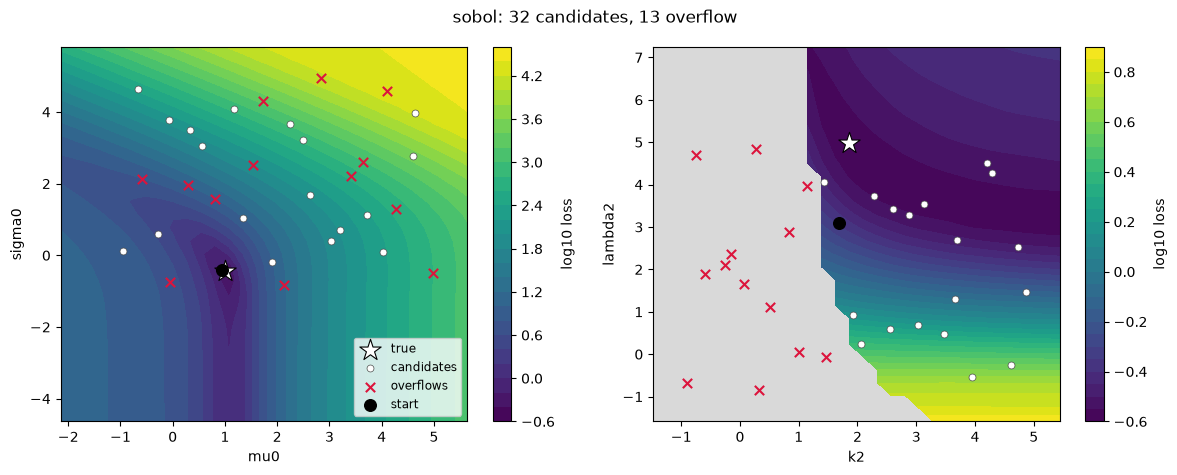

In [29]:
best = int(np.nanargmin(losses))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), layout="tight")
for ax, pair in zip(axs, projections):
    drawn = draw_slice(ax, pair)
    x = candidates[:, names.index(pair[0])]
    y = candidates[:, names.index(pair[1])]
    ax.scatter(
        x[~failed],
        y[~failed],
        s=25,
        color="white",
        edgecolor="0.3",
        linewidth=0.5,
        label="candidates",
    )
    ax.scatter(
        x[failed], y[failed], marker="x", color="crimson", s=45, label="overflows"
    )
    ax.scatter(x[best], y[best], marker="o", s=70, color="black", label="start")
    fig.colorbar(drawn, ax=ax, label="log10 loss")
axs[0].legend(fontsize="small", loc="lower right")
fig.suptitle(f"sobol: 32 candidates, {int(failed.sum())} overflow")
plt.show()

The search that we recorded above comes next. It starts from the center of the
same box. 13 of the 32 candidates of that box overflow, but none of the 100
evaluations of the search does. A point that overflows is never returned.

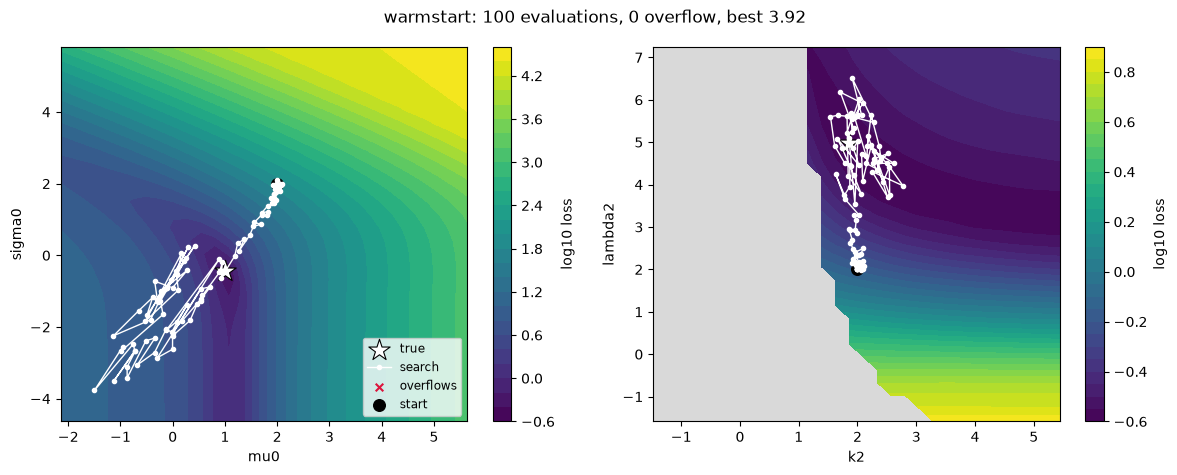

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), layout="tight")
for ax, pair in zip(axs, projections):
    drawn = draw_slice(ax, pair)
    x = search_path[:, names.index(pair[0])]
    y = search_path[:, names.index(pair[1])]
    ax.plot(
        x, y, color="white", linewidth=1.0, marker="o", markersize=3, label="search"
    )
    ax.scatter(
        x[overflowed],
        y[overflowed],
        marker="x",
        color="crimson",
        s=30,
        label="overflows",
    )
    ax.scatter(x[0], y[0], marker="o", s=70, color="black", label="start")
    fig.colorbar(drawn, ax=ax, label="log10 loss")
axs[0].legend(fontsize="small", loc="lower right")
fig.suptitle(
    f"warmstart: {len(scores)} evaluations, {int(overflowed.sum())} overflow, "
    f"best {scores.min():.3g}"
)
plt.show()

### Did the training work?

The criterion is not the distance to a true hyperparameter. A real elicitation
has no true value. The criterion is whether the model reproduces the expert
data.

The loss over the epochs shows what the table hides. A start value that is
merely poor gives a higher curve. A start value that cannot train gives a curve
that stops, and two of the three curves stop.

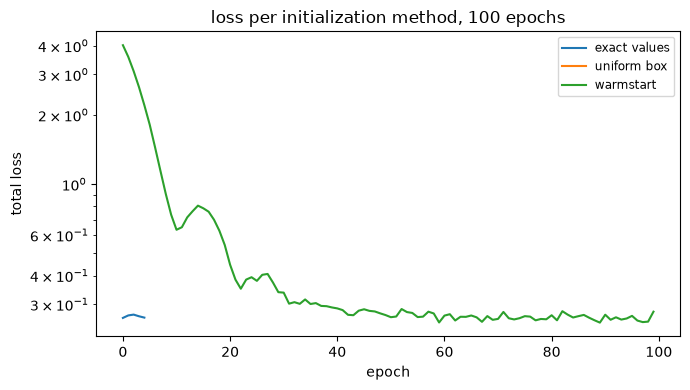

In [31]:
fig, ax = plt.subplots(figsize=(7, 4), layout="tight")
for label, fitted in fits.items():
    trace = np.ravel(
        np.asarray(fitted.results.history_stats.loss.total_loss.sel(replication=0))
    )
    ax.plot(trace, label=label)
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("total loss")
ax.legend(fontsize="small")
ax.set_title("loss per initialization method, 100 epochs")
plt.show()

We cannot compare the runs that stopped any further, so we follow only the warm
start from here. One hundred epochs are not enough to converge, so we train it
for 600, and then ask whether the model reproduces the expert data.
[`elicits`][elicito.plots.elicits] draws the expert-elicited value against the
model-simulated one, for each of the three targets. A point on the diagonal is
a statistic that the model reproduces.

In [32]:
long_run = build(
    el.initializer(
        method="warmstart",
        iterations=100,
        distribution=el.initializers.uniform(radius=3, mean=2),
    ),
    epochs=600,
)
fit_long = long_run.fit(expert)

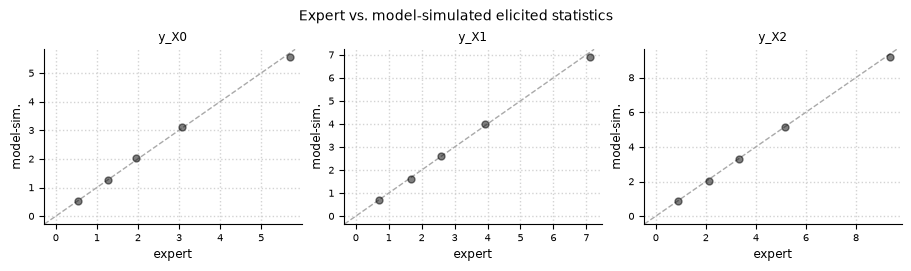

In [33]:
fit_long.plot.elicits(cols=3, figsize=(9, 2.6))
plt.show()

### Watch the hyperparameters

This model has an oracle, so we know the true hyperparameters here. We compare
each one with its true value, and we see what the expert data can pin down.

$\mu_0$, $\mu_1$, $\sigma_0$ and $\sigma_1$ arrive near their true values. The
other two do not: $k_2$ ends near 7.1 against a true 2, and $\lambda_2$ near
2.4 against a true 5.

This is not a failure of the initialization, and not a lack of epochs. The
fitted point reaches 0.255, below the 0.262 that the run from the true values
reached before it stopped. The 15 elicited quantiles, at three values of the
predictor, do not identify six hyperparameters: a smaller Weibull scale with a
much larger shape produces the same predictive quantiles. Query the parameters
themselves if you need every hyperparameter back.

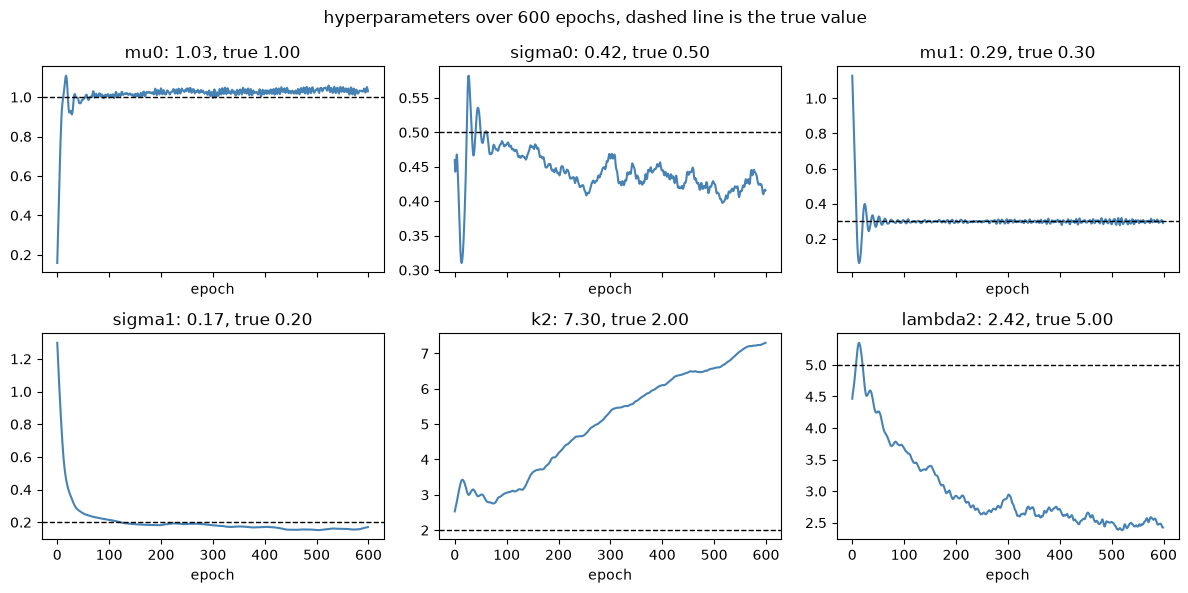

In [34]:
history = long_run.results.history_stats.hyperparameter.sel(replication=0)

fig, axes = plt.subplots(2, 3, figsize=(12, 6), layout="tight", sharex=True)
for ax, name in zip(np.ravel(axes), truth):
    trace = np.ravel(np.asarray(history[name].values))
    ax.plot(trace, color="steelblue")
    ax.axhline(truth[name], color="black", linestyle="--", linewidth=1)
    ax.set_title(f"{name}: {trace[-1]:.2f}, true {truth[name]:.2f}")
    ax.set_xlabel("epoch")
fig.suptitle("hyperparameters over 600 epochs, dashed line is the true value")
plt.show()

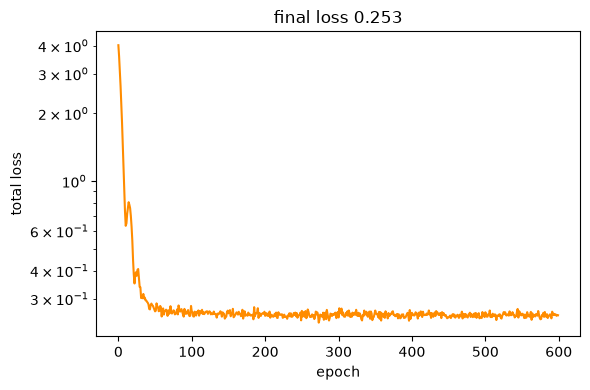

In [35]:
loss_trace = np.ravel(
    np.asarray(long_run.results.history_stats.loss.total_loss.sel(replication=0))
)
fig, ax = plt.subplots(figsize=(6, 4), layout="tight")
ax.plot(loss_trace, color="darkorange")
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("total loss")
ax.set_title(f"final loss {loss_trace[-1]:.3f}")
plt.show()

## Which one to choose

Part 1, two hyperparameters, 300 epochs:

| method       | final loss | seconds |
| :----------- | ---------: | ------: |
| exact values |      0.088 |     4.4 |
| uniform box  |      0.088 |     5.5 |
| far box      |      0.088 |     5.6 |
| warmstart    |      0.088 |     4.3 |

Part 2, six hyperparameters and a likelihood that overflows, 100 epochs:

| method       | final loss | seconds |
| :----------- | ---------: | ------: |
| exact values |      0.262 |     1.3 |
| uniform box  |      2.361 |     3.4 |
| warmstart    |      0.277 |     3.0 |

+ **`warmstart`** is the default method. It needs no gradient, so it cannot
  diverge on a model that overflows. In part 2 it is the only run that trains
  for all 100 epochs. Each evaluation costs one forward simulation.
+ Use **exact values** when you know them. Nothing is cheaper.
+ Use a **`uniform` box** that you center yourself when you know the order of
  magnitude of the hyperparameters. Add `warmup_epochs` to reject a candidate
  that diverges in the first epochs.

Part 1 also shows the limit of all of this. On a surface with one minimum, and
with a signal above the sampling error everywhere the box sits, every method
reaches the same loss. The start value earns its cost only where the training
cannot repair it: where the effect of a hyperparameter falls below the error of
the loss estimate, as on the flat floor of part 1, or where the draws overflow,
as in part 2.